# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ladinski/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked Actions and Reason Codes

**Project:** Refresh / Content Opportunity Scoring

**Objective:** Turn a validated page-decline ranking model into a transparent, human-reviewed editorial action queue.

### Model Evidence

The Week 5 Random Forest achieved Precision@50 of 0.700 on a client-holdout test set of 7,115 pages, compared with 0.480 for the Week 4 hand-written baseline evaluated on the same holdout.

The model correctly identified 35 declining pages among its 50 highest-ranked recommendations. However, 15 were not labeled as declining, so model scores must not be treated as automatic instructions.

### Recommended Action Types

| Page archetype | Recommended action | Reason code |
|---|---|---|
| High predicted decline risk with meaningful search impressions | Investigate declining search performance and review content freshness | `REVIEW_DECLINE` |
| Page ranking in positions 4–10 with CTR below its position-bucket benchmark | Review search title, description, and search intent | `REVIEW_CTR` |
| Mature page with an older last-update date and existing visibility | Audit factual accuracy, missing sections, and outdated references | `REVIEW_FRESHNESS` |
| Page ranking in positions 11–20 with measurable search demand | Review topical relevance, internal links, and content coverage | `REVIEW_POSITION` |
| Page with weak or incomplete measurement coverage | Validate data quality before recommending editorial changes | `CHECK_DATA` |

These are proposed investigation categories, not verified diagnoses or evidence that a specific intervention will increase traffic.

### Ranking and Prioritization

The primary ranking signal will be the Random Forest's predicted decline score. Pages will be ranked from highest to lowest score.

The score estimates the model's classification tendency and has not been calibrated as a real-world probability of future decline.

Reason codes will be derived from observed page characteristics to help reviewers understand why a page merits investigation.

### Decay and Refresh Insight

FlyRank's March 2026 research paper observed stronger search-performance indicators among recently refreshed mature content than among some stale-content comparison groups.

However, this does not establish that refreshing caused the full performance difference. Editorial teams may have preferentially refreshed pages that were already more promising.

Therefore, content freshness should be treated as a review signal rather than an automatic instruction to rewrite older pages.

### Human Decision

An SEO specialist should inspect each recommended page, identify the actual problem, estimate potential value, and decide whether any editorial intervention is appropriate.

A high model score alone is never sufficient justification for publishing changes.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 2. Intended Use, Limitations, and Cost/Value

### Intended Use

This playbook is designed to support SEO specialists, content editors, and content managers in deciding which existing pages deserve further investigation.

The Random Forest model ranks content pages according to patterns associated with the observed decline label. Reason codes provide interpretable review suggestions based on page characteristics.

The system is intended for **human-reviewed editorial prioritization**, not autonomous content optimization.

### Recommended Workflow

1. Generate the ranked review queue from the validated model.
2. Inspect the highest-ranked pages and their reason codes.
3. Confirm that the underlying search-performance data is reliable.
4. Review each page's historical performance, search intent, freshness, and content quality.
5. Estimate the potential benefit and editorial effort.
6. Approve, modify, defer, or reject the suggested action.
7. Measure outcomes after any approved intervention.

### Evidence and Validation Limits

The model achieved Precision@50 of 0.700 on one client-holdout evaluation, compared with 0.480 for the Week 4 baseline evaluated on the same holdout.

However, the Week 6 audit identified several limitations:

- The evaluation used one grouped train/test split, so results may vary across client populations.
- Fifteen of the 50 highest-ranked recommendations were false positives against the observed decline label.
- The target represents observed decline, not independently verified future deterioration.
- Temporal availability of all six input features has not been fully established.
- Model scores are not calibrated probabilities.
- The model does not estimate the causal effect of refreshing, rewriting, or otherwise optimizing a page.
- The anonymized sample may not represent every content portfolio, language, industry, or website.

### Cost and Value Considerations

A model recommendation should be considered alongside the cost of investigating and editing the page.

| Factor | Practical interpretation |
|---|---|
| Review effort | Time required to diagnose the page |
| Editorial effort | Time needed to research, edit, and quality-check |
| Existing visibility | Impressions and clicks that make the page worth investigating |
| Business relevance | Whether the page supports important topics, audiences, or conversion goals |
| Confidence in diagnosis | Whether the identified problem is confirmed by a human reviewer |
| Opportunity cost | Other pages that could receive the same editorial resources |

**Illustrative decision example:**

If an editor has two hours available, reviewing five high-priority pages for 15 minutes each would require approximately 75 minutes, leaving time to investigate the most promising confirmed issue.

This is a planning example, not a measured productivity result.

The model's ranking score should not be multiplied directly by impressions or converted into expected revenue. Such calculations would imply knowledge about intervention effectiveness that the current evaluation does not establish.

### Decision Rule

A page should be prioritized for editorial work only when:

- Its underlying performance data is sufficiently reliable.
- A human reviewer confirms an actionable issue.
- There is a reasonable connection between the proposed action and the observed problem.
- The expected benefit justifies the estimated effort.
- The action does not introduce factual, legal, editorial, or SEO risks.

### Research Scope

This is a non-production research prototype.

It demonstrates how an ML ranking can become a transparent content-review workflow. It does not demonstrate a deployed optimization service, measured traffic uplift, or automated editorial improvements.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 3. Human Review Rules and No-Go Cases

### Human-in-the-Loop Policy

The Content Action Playbook is a decision-support tool. Every recommended action requires human review and approval before implementation.

The Random Forest identifies pages that resemble previously declining content, but it cannot independently determine whether an editorial change is necessary, beneficial, or safe.

### Human Review Workflow

| Stage | Human responsibility | Possible outcome |
|---|---|---|
| 1. Data verification | Confirm impressions, CTR, position, and update history are reliable | Continue or flag data issue |
| 2. Page inspection | Read the page and assess search intent, factual accuracy, and content quality | Confirm or reject diagnosis |
| 3. Action selection | Choose whether to refresh, improve snippets, strengthen internal links, or take no action | Proposed intervention |
| 4. Cost/value assessment | Estimate effort and potential business relevance | Prioritize or defer |
| 5. Editorial approval | Verify factual accuracy, brand consistency, and compliance | Approve or reject |
| 6. Post-action monitoring | Review subsequent performance without assuming causality | Continue monitoring or investigate |

### Explicit No-Go List

The following activities must **not** be automated by this research prototype:

1. **Automatic publishing or rewriting:** Never modify live content based solely on a model score.
2. **Automatic deletion or deindexing:** Never remove pages, change canonical URLs, or modify indexing directives without authorized human approval.
3. **Unverified factual changes:** Never invent statistics, references, product claims, or factual updates.
4. **Blind SEO manipulation:** Never automatically insert keywords, generate backlinks, or change metadata without verifying relevance and quality.
5. **High-stakes content changes:** Medical, legal, financial, and other sensitive material requires qualified review.
6. **Actions based on missing data:** Do not prescribe changes when tracking is incomplete or unreliable.
7. **Causal or financial guarantees:** Do not promise traffic increases, ranking gains, conversions, or revenue.
8. **Cross-client data exposure:** Never expose confidential page details or performance data between clients.

### Handling False Positives

The Week 6 evaluation found 15 non-declining pages among the 50 highest-ranked model recommendations.

Reviewers must therefore be able to reject recommendations, even when their model scores are high.

A rejected recommendation should be retained as feedback for evaluating model behavior, not automatically treated as proof that the reviewer or model was incorrect.

### Escalation Rules

Escalate a recommendation when:

- The page contains regulated or sensitive information.
- Performance measurements are contradictory or incomplete.
- A proposed change could affect indexing, navigation, or other important website behavior.
- The review requires expertise beyond the editor's authority.
- The proposed action involves substantial cost or business risk.

### Final Approval Requirement

Every generated queue record will include:

- `requires_human_review = True`
- `approval_status = "PENDING_REVIEW"`

The notebook may generate recommendations, explanations, and research exports, but it must not execute website changes.

**Operational principle:** Model scores prioritize investigation. Humans authorize actions.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 4. Monitoring and Retraining Triggers

### Monitoring Objective

The Content Action Playbook should remain useful, explainable, and reliable as content performance, client portfolios, and search behavior change.

Monitoring is designed to identify deteriorating ranking quality, unreliable data, changing input distributions, and recommendations that require reassessment.

These are proposed operational checks for future implementation, not evidence of an existing production monitoring system.

### Proposed Monitoring Plan

| Area | Metric or check | Frequency | Proposed trigger | Response |
|---|---|---|---|---|
| Ranking quality | Precision@50 on reviewed, labeled examples | Monthly when labels are available | Below 0.60 | Investigate performance |
| Data quality | Missing or invalid feature values | Every queue generation | More than 5% missing in any key feature | Flag affected records |
| Input drift | Feature distribution changes | Monthly | PSI above 0.20 for a key feature | Investigate population changes |
| Client generalization | Precision@50 across unseen clients | Quarterly when sufficient labels exist | Material decline from the 0.70 research baseline | Repeat grouped validation |
| Review usefulness | Human acceptance and rejection rates | Monthly | Rejection rate above 40% | Examine reason codes and ranking |
| Editorial capacity | Pending review queue size | Weekly | Queue exceeds available reviewer capacity | Reduce review batch size |
| Intervention outcomes | Impressions, clicks, CTR, and position after approved changes | 30, 60, and 90 days | Repeated underperformance | Review action strategy |

All thresholds are illustrative investigation triggers, not statistically validated operating limits.

### Retraining Triggers

Consider retraining when:

1. Repeated evaluations show deterioration in ranking performance.
2. New clients or content categories differ substantially from the original training population.
3. Data collection or feature definitions change.
4. Human-reviewed errors reveal persistent failure patterns.
5. Sufficient new labeled examples become available to support an updated evaluation.

Retraining should not happen automatically after one unusual metric or isolated prediction error.

### Retraining Procedure

1. Investigate the observed problem and verify data quality.
2. Define a consistent prediction time and outcome window.
3. Reconstruct historical features using only information available at prediction time.
4. Prepare updated training and evaluation datasets.
5. Use client-grouped validation and, where possible, forward-in-time testing.
6. Compare the candidate model against the existing model and a simple baseline.
7. Review false positives, false negatives, and performance differences across client groups.
8. Document results and obtain human approval before replacing the model.

### Minimum Evidence for a Model Update

A replacement model should demonstrate useful improvements on appropriate held-out data without creating unacceptable increases in false positives, review burden, or performance disparities.

Any reported improvement should include the sample size, evaluation method, metric definition, and limitations.

### Monitoring Limitations

The current 30,000-page starter dataset is a research snapshot. It does not provide a live stream of future outcomes, human approval records, or measured editorial intervention effects.

Consequently, this notebook can define monitoring logic and retraining criteria but cannot establish real-world stability or business impact.

### Final Policy

Monitoring may generate alerts and investigation tasks.

Retraining, model replacement, and editorial publication require explicit human review and approval.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 5. Ranked Queue and Research Exports

This section generates a reproducible content-review queue from the validated Random Forest model.

The queue contains model-based rankings, descriptive reason codes, suggested editorial investigations, and mandatory human-review requirements.

For methodological consistency, the primary evaluation export uses the client-holdout test set from Week 6. This allows the exported metrics to remain connected to the previously reported validation results.

The queue is a research artifact, not a production recommendation system. Reason codes describe observable page characteristics; they do not establish the causes of declining performance.

The CSV export is stored in `work/outputs/` and excluded from Git according to repository policy. A metrics JSON and reusable figure will provide traceability for the final research paper.

In [1]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import numpy as np
import pandas as pd
import json
import subprocess
from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Locate dataset: Colab or cloned repository
repo = Path("/content/flyrank-ml-internship")
data_path = repo / "data/raw/content_refresh_anonymized.csv"

if not data_path.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/Ladinski/flyrank-ml-internship.git",
            str(repo)
        ],
        check=True
    )

df = pd.read_csv(data_path)
df["is_declining_label"] = (
    df["trend_direction"] == "down"
).astype(int)

features = [
    "impressions_90d",
    "avg_position",
    "ctr",
    "content_age_days",
    "days_since_last_update",
    "word_count"
]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df,
        df["is_declining_label"],
        groups=df["client_id"]
    )
)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
)

model.fit(
    df.iloc[train_idx][features],
    df.iloc[train_idx]["is_declining_label"]
)

queue = df.iloc[test_idx].copy()
queue["model_score"] = model.predict_proba(
    queue[features]
)[:, 1]

queue = queue.sort_values(
    "model_score",
    ascending=False,
    kind="stable"
).reset_index(drop=True)

queue["rank"] = np.arange(1, len(queue) + 1)

# Determine review action using transparent heuristics
def assign_action(row):
    if pd.isna(row["impressions_90d"]) or pd.isna(row["ctr"]):
        return "CHECK_DATA", "Verify measurement coverage"

    if row["impressions_90d"] < 100:
        return "CHECK_DATA", "Verify search demand and data quality"

    if 4 <= row["avg_position"] <= 10 and row["ctr"] < 0.20:
        return "REVIEW_CTR", "Review search snippet and query intent"

    if row["content_age_days"] >= 180 and row["days_since_last_update"] >= 90:
        return "REVIEW_FRESHNESS", "Inspect mature content for outdated information"

    if 11 <= row["avg_position"] <= 20:
        return "REVIEW_POSITION", "Review relevance, coverage, and internal links"

    return "REVIEW_DECLINE", "Investigate observed search-performance signals"

queue[["reason_code", "action_label"]] = queue.apply(
    lambda row: pd.Series(assign_action(row)),
    axis=1
)

queue["requires_human_review"] = True
queue["approval_status"] = "PENDING_REVIEW"

queue_export = queue[
    [
        "rank",
        "model_score",
        "impressions_90d",
        "avg_position",
        "ctr",
        "content_age_days",
        "days_since_last_update",
        "reason_code",
        "action_label",
        "requires_human_review",
        "approval_status"
    ]
]

print("Ranked queue rows:", len(queue_export))
print("\nReason code distribution:")
print(queue_export["reason_code"].value_counts())

display(queue_export.head(10).round(3))


Ranked queue rows: 7115

Reason code distribution:
reason_code
CHECK_DATA          2684
REVIEW_DECLINE      2027
REVIEW_CTR           895
REVIEW_POSITION      835
REVIEW_FRESHNESS     674
Name: count, dtype: int64


,rank,model_score,impressions_90d,avg_position,ctr,content_age_days,days_since_last_update,reason_code,action_label,requires_human_review,approval_status
0,1,0.984,3445,39.0,0.09,280,104,REVIEW_FRESHNESS,Inspect mature content for outdated information,True,PENDING_REVIEW
1,2,0.960,807,24.0,0.25,280,104,REVIEW_FRESHNESS,Inspect mature content for outdated information,True,PENDING_REVIEW
2,3,0.959,2663,6.5,0.08,223,102,REVIEW_CTR,Review search snippet and query intent,True,PENDING_REVIEW
3,4,0.957,1828,5.6,0.22,275,104,REVIEW_FRESHNESS,Inspect mature content for outdated information,True,PENDING_REVIEW
4,5,0.952,1290,12.4,0.00,280,104,REVIEW_FRESHNESS,Inspect mature content for outdated information,True,PENDING_REVIEW
5,6,0.952,209,20.0,0.00,271,104,REVIEW_FRESHNESS,Inspect mature content for outdated information,True,PENDING_REVIEW
6,7,0.951,836,6.8,0.24,280,104,REVIEW_FRESHNESS,Inspect mature content for outdated information,True,PENDING_REVIEW
7,8,0.951,1531,22.0,0.00,280,14,REVIEW_DECLINE,Investigate observed search-performance signals,True,PENDING_REVIEW
8,9,0.949,1596,6.2,0.31,275,104,REVIEW_FRESHNESS,Inspect mature content for outdated information,True,PENDING_REVIEW
9,10,0.948,2004,39.1,0.00,272,104,REVIEW_FRESHNESS,Inspect mature content for outdated information,True,PENDING_REVIEW


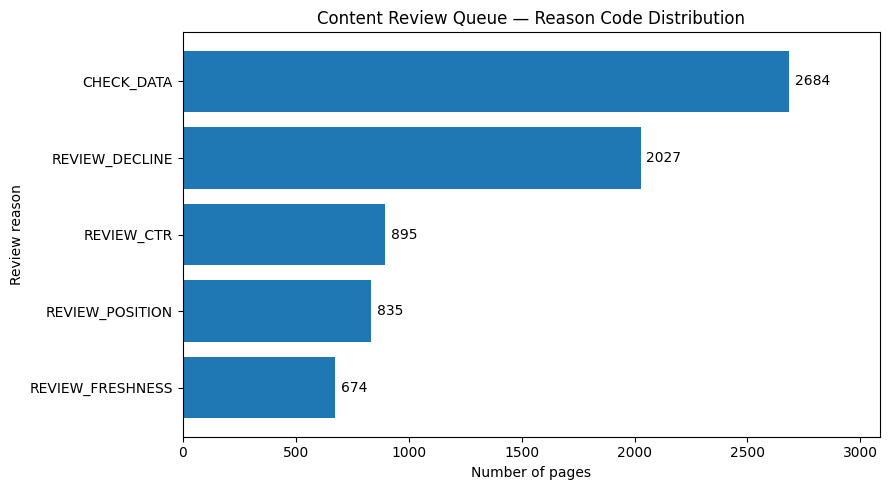

Queue CSV: /content/flyrank-ml-internship/work/outputs/w07_ranked_action_queue.csv
Metrics JSON: /content/flyrank-ml-internship/work/outputs/w07_action_metrics.json
Figure: /content/flyrank-ml-internship/work/figures/w07_reason_code_distribution.png
Precision@50: 0.7
Exports completed.


In [2]:

import json
import matplotlib.pyplot as plt
from pathlib import Path

# Output directories inside the repository
outputs_dir = repo / "work" / "outputs"
figures_dir = repo / "work" / "figures"

outputs_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Export full ranked queue (ignored by Git)
queue_path = outputs_dir / "w07_ranked_action_queue.csv"
queue_export.to_csv(queue_path, index=False)

# 2. Compute evaluation metrics
top50 = queue.head(50)

precision_50 = float(
    top50["is_declining_label"].mean()
)

reason_counts = {
    str(key): int(value)
    for key, value in
    queue_export["reason_code"].value_counts().items()
}

metrics = {
    "project": "Refresh / Content Opportunity Scoring",
    "validation": "Client-holdout GroupShuffleSplit",
    "random_state": 42,
    "training_pages": int(len(train_idx)),
    "test_pages": int(len(test_idx)),
    "ranked_pages": int(len(queue_export)),
    "precision_at_50": precision_50,
    "top_50_correct": int(
        top50["is_declining_label"].sum()
    ),
    "top_50_false_positives": int(
        50 - top50["is_declining_label"].sum()
    ),
    "reason_code_counts": reason_counts,
    "limitations": [
        "Observed decline classification, not future causal uplift",
        "Single client-holdout split",
        "Model probabilities are uncalibrated",
        "Temporal feature availability is not fully verified",
        "All actions require human approval"
    ]
}

metrics_path = outputs_dir / "w07_action_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

# 3. Save a figure for the research paper
counts = queue_export["reason_code"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(counts.index, counts.values)

ax.set_title("Content Review Queue — Reason Code Distribution")
ax.set_xlabel("Number of pages")
ax.set_ylabel("Review reason")

for i, value in enumerate(counts.values):
    ax.text(value + 25, i, str(value), va="center")

ax.set_xlim(0, counts.max() * 1.15)
plt.tight_layout()

figure_path = figures_dir / "w07_reason_code_distribution.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

print("Queue CSV:", queue_path)
print("Metrics JSON:", metrics_path)
print("Figure:", figure_path)
print("Precision@50:", precision_50)
print("Exports completed.")


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.